# Import libraries

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.6/383.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.8/231.8 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 3.6 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme()

# dataset
from sklearn.datasets import load_breast_cancer

# machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression # Linear Regression
from sklearn.linear_model import Ridge # Ridge Regression
from sklearn.linear_model import Lasso # Lasso Regression
from sklearn.tree import DecisionTreeRegressor # Decision Tree
from sklearn.ensemble import RandomForestRegressor # Random Forest
from sklearn.ensemble import GradientBoostingRegressor # Gradient Boosting
from sklearn.ensemble import ExtraTreesRegressor # Extra Trees
from sklearn.ensemble import AdaBoostRegressor # AdaBoost
from xgboost import XGBRegressor # XGBoost
from sklearn.metrics import mean_squared_error # MSE
from sklearn.ensemble import RandomForestRegressor # Random Forest
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV # GridSearch CV
import optuna # optuna (Bayesian optimization)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# ignore warnings
import warnings
warnings.filterwarnings('ignore')

---

# Viewing dataset

In [ ]:
# connect with google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# load dataset
file_path = '/content/drive/MyDrive/0003. FTU SUBJECTS/010. PHÂN TÍCH DỮ LIỆU/04. CUSTOMER SEGMENTATION PROJECT/02. NOTEBOOK/04. TRANSACTION/02. Predictive Analytics/01. TẠO DATASET/predictive_analytics.csv'
df = pd.read_csv(file_path)
display(df.head())

,customer_id,past_3_years_bike_related_purchases,tenure,Age,postcode,property_valuation,transaction_count,total_spend,avg_spend,std_spend,...,job_industry_category,wealth_segment,deceased_indicator,owns_car,address,state,country,preferred_product_line,preferred_brand,high_value_customer
0,1,93,11.0,72,2016.0,10.0,11.0,9084.45,825.859091,601.942740,...,Health,Mass Customer,N,Yes,060 Morning Avenue,NSW,Australia,Standard,Giant Bicycles,1
1,2,81,16.0,45,2153.0,10.0,3.0,4149.07,1383.023333,620.398494,...,Financial Services,Mass Customer,N,Yes,6 Meadow Vale Court,NSW,Australia,Standard,WeareA2B,0
2,3,61,15.0,71,NaN,8.0,8.0,9888.23,1236.028750,539.899300,...,Property,Mass Customer,N,Yes,NaN,NaN,NaN,Standard,Norco Bicycles,1
3,4,33,7.0,64,4211.0,9.0,2.0,1047.72,523.860000,64.629560,...,IT,Mass Customer,N,No,0 Holy Cross Court,QLD,Australia,Standard,Giant Bicycles,0
4,5,56,8.0,48,2448.0,4.0,6.0,5903.20,983.866667,522.823431,...,Health,Affluent Customer,N,Yes,17979 Del Mar Point,NSW,Australia,Road,Norco Bicycles,0


---

# Inspect Dataset

In [ ]:
# Inspect Dataset
print(df.info())
print()
print(df.describe().T)
print()
print(df.describe(include='object').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 28 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   customer_id                          3999 non-null   int64  
 1   past_3_years_bike_related_purchases  3999 non-null   int64  
 2   tenure                               3999 non-null   float64
 3   Age                                  3999 non-null   int64  
 4   postcode                             3995 non-null   float64
 5   property_valuation                   3999 non-null   float64
 6   transaction_count                    3999 non-null   float64
 7   total_spend                          3999 non-null   float64
 8   avg_spend                            3999 non-null   float64
 9   std_spend                            3999 non-null   float64
 10  total_profit                         3999 non-null   float64
 11  avg_profit                    

# Xác định features and target

In [ ]:
# Tính toán CLV hiện tại (dựa trên tổng lợi nhuận)
df['current_clv'] = df['total_profit']

# Chọn các features để dự đoán CLV
clv_predictors = [
    'Age', 'gender', 'job_industry_category', 'wealth_segment',
    'owns_car', 'property_valuation', 'transaction_count',
    'avg_spend', 'std_spend', 'online_order_ratio'
]

X = df[clv_predictors]
y = df['current_clv']

In [ ]:
# Shape
print(f'Shape of X: {X.shape}')
print(f'Shape of y: {y.shape}')

Shape of X: (3999, 10)
Shape of y: (3999,)


In [ ]:
nominal_features = X.select_dtypes(include=['object']).columns
print(nominal_features)

print()
ordinal_features = 'wealth_segment'
# remove
nominal_features = nominal_features.drop(ordinal_features)

Index(['gender', 'job_industry_category', 'wealth_segment', 'owns_car'], dtype='object')



In [ ]:
print(f'Nominal features: {nominal_features}')
print(f'Ordinal features: {ordinal_features}')

Nominal features: Index(['gender', 'job_industry_category', 'owns_car'], dtype='object')
Ordinal features: wealth_segment


In [ ]:
# numerical features
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
print(numerical_features)

Index(['Age', 'property_valuation', 'transaction_count', 'avg_spend',
       'std_spend', 'online_order_ratio'],
      dtype='object')


In [ ]:
# Standard for Numerical
scaler = StandardScaler()
X[numerical_features] = scaler.fit_transform(X[numerical_features])

# Get dummies with norminal
X = pd.get_dummies(X, columns=nominal_features, drop_first=True)

# Mapping with ordinal
mapping = {
    'High Net Worth': 2,
    'Affluent Customer': 1,
    'Mass Customer': 0
}
X[ordinal_features] = X[ordinal_features].map(mapping)

In [ ]:
# Feature selection với Random Forest
print("Feature selection...")
def select_features_random_forest(X, y, n_features=5):
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X, y)

    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1][:n_features]

    selected_features = X.columns[indices]
    selected_importances = importances[indices]

    feature_importance_df = pd.DataFrame({
        'Feature': selected_features,
        'Importance': selected_importances
    })
    return selected_features, feature_importance_df

selected_features, feature_importance_df = select_features_random_forest(X, y)
print("\nTop 10 Important Features:")
print(feature_importance_df)

Feature selection...

Top 10 Important Features:
              Feature  Importance
0   transaction_count    0.580227
1           avg_spend    0.303482
2           std_spend    0.034664
3                 Age    0.022920
4  property_valuation    0.015673


In [ ]:
# Select features
X = X[selected_features]

In [ ]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Shape
print(f'Shape of X_train: {X_train.shape}')
print(f'Shape of X_test: {X_test.shape}')
print(f'Shape of y_train: {y_train.shape}')
print(f'Shape of y_test: {y_test.shape}')

Shape of X_train: (3199, 5)
Shape of X_test: (800, 5)
Shape of y_train: (3199,)
Shape of y_test: (800,)


# Bayesian optimization XGBoost

In [ ]:
# Define the objective function for Optuna
def objective(trial):
    # Định nghĩa không gian tham số
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 10.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 10.0)
    }

    # Train XGBoost Regressor với các tham số được đề xuất
    model = XGBRegressor(
        objective='reg:squarederror',  # Mục tiêu tối ưu hóa cho bài toán hồi quy
        random_state=42,
        **params
    )
    model.fit(X_train, y_train)

    # Đánh giá mô hình trên tập kiểm thử
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)

    return r2

In [ ]:
# Create optuna study
study = optuna.create_study(direction='maximize')

# Optimize the objective function
study.optimize(objective, n_trials=50)

[I 2025-03-15 07:42:06,648] A new study created in memory with name: no-name-6bed903a-ec0b-47ad-9aa9-e927e0b7ccfc
[I 2025-03-15 07:42:08,551] Trial 0 finished with value: 0.8460855983593198 and parameters: {'learning_rate': 0.04031808143599497, 'n_estimators': 154, 'max_depth': 4, 'subsample': 0.729092570485828, 'colsample_bytree': 0.9223660750579141, 'gamma': 0.35028135537497784, 'reg_alpha': 9.53937740876876, 'reg_lambda': 9.161356871585033}. Best is trial 0 with value: 0.8460855983593198.
[I 2025-03-15 07:42:13,251] Trial 1 finished with value: 0.8057079241218251 and parameters: {'learning_rate': 0.0693614793068442, 'n_estimators': 198, 'max_depth': 10, 'subsample': 0.906232637527417, 'colsample_bytree': 0.6658449633155825, 'gamma': 4.29108759627699, 'reg_alpha': 1.51683390162349, 'reg_lambda': 2.53254165384456}. Best is trial 0 with value: 0.8460855983593198.
[I 2025-03-15 07:42:14,947] Trial 2 finished with value: 0.8105973527392231 and parameters: {'learning_rate': 0.067917881603

In [ ]:
# Best hyperparameters
best_params = study.best_params
print("Best Hyperparameters:", best_params)

min_mse = study.best_value
print("The min value of MSE", min_mse)

Best Hyperparameters: {'learning_rate': 0.03622441813405196, 'n_estimators': 201, 'max_depth': 4, 'subsample': 0.8824849498982681, 'colsample_bytree': 0.8316384647397943, 'gamma': 2.27206824678254, 'reg_alpha': 6.855719660930594, 'reg_lambda': 9.403669503925387}
The min value of MSE 0.8482042005454589


In [ ]:
# Evaluate the best model
best_model = XGBRegressor(
    objective='reg:squarederror',  # Mục tiêu tối ưu hóa cho bài toán hồi quy
    random_state=42,
    **best_params  # Sử dụng các siêu tham số tốt nhất từ Optuna
)
best_model.fit(X_train, y_train)

# Make predictions
y_pred_best = best_model.predict(X_test)

# Evaluate the best model using MSE and R²
mse = mean_squared_error(y_test, y_pred_best)
r2 = r2_score(y_test, y_pred_best)

print(f"Mean Squared Error (MSE) of best model: {mse:.4f}")
print(f"R-squared (R²) of best model: {r2:.4f}")

Mean Squared Error (MSE) of best model: 593374.7668
R-squared (R²) of best model: 0.8482


In [ ]:
# Lấy feature importance
clv_feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

clv_feature_importance.sort_values(by='Importance', ascending=False, inplace=True)
print("Feature Importance from the best XGBoost:")
print(clv_feature_importance)

Feature Importance from the best XGBoost:
              Feature  Importance
0   transaction_count    0.606699
1           avg_spend    0.330294
2           std_spend    0.041070
3                 Age    0.012098
4  property_valuation    0.009838


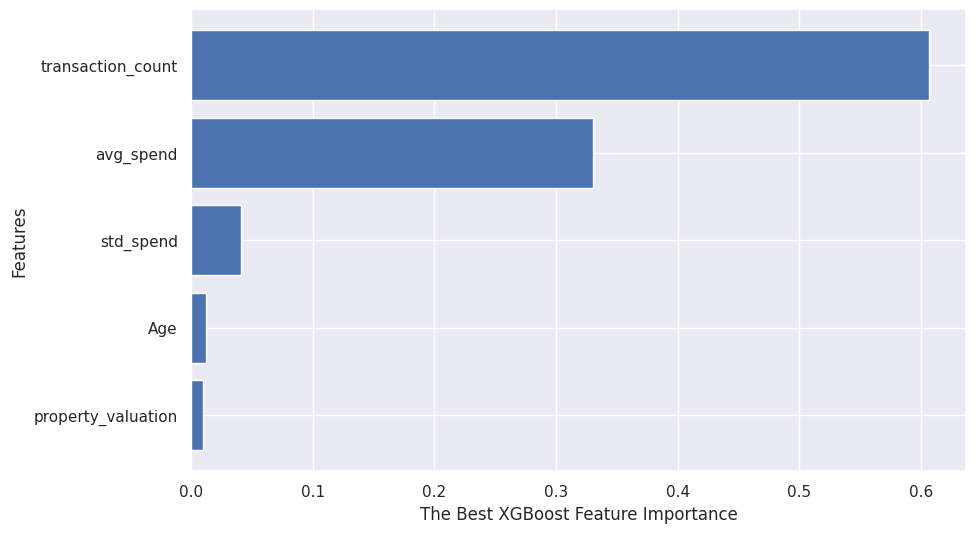

In [ ]:
# Plot features importance
plt.figure(figsize=(10,6))
plt.barh(clv_feature_importance['Feature'], clv_feature_importance['Importance'])
plt.gca().invert_yaxis()
plt.xlabel("The Best XGBoost Feature Importance")
plt.ylabel("Features")
plt.show()

---

# Train ML model by A-B testing

In [ ]:
# 1. Feature selection với Random Forest
print("1. Feature selection...")
def select_features_random_forest(X, y, n_features=5):
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X, y)

    importances = rf.feature_importances_
    indices = np.argsort(importances)[::-1][:n_features]

    selected_features = X.columns[indices]
    selected_importances = importances[indices]

    feature_importance_df = pd.DataFrame({
        'Feature': selected_features,
        'Importance': selected_importances
    })
    return selected_features, feature_importance_df

selected_features, feature_importance_df = select_features_random_forest(X, y)
print("\nTop 5 Important Features:")
print(feature_importance_df)

1. Feature selection...

Top 5 Important Features:
              Feature  Importance
0   transaction_count    0.581509
1           avg_spend    0.315986
2           std_spend    0.047580
3                 Age    0.032656
4  property_valuation    0.022269


In [ ]:
# Split data
print("\n2. Split data...")
X = X[selected_features]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


2. Split data...


In [ ]:
# A/B Testing with Multiple Models
print("\n. A/B Testing...")
maxr2 = -float('inf')
best_model = None
best_model_name = None

seed = 42
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(random_state=seed),
    'Lasso': Lasso(random_state=seed),
    'DecisionTree': DecisionTreeRegressor(random_state=seed, max_depth=5),
    'RandomForest': RandomForestRegressor(random_state=seed),
    'GradientBoosting': GradientBoostingRegressor(random_state=seed),
    'ExtraTrees': ExtraTreesRegressor(random_state=seed),
    'AdaBoost': AdaBoostRegressor(random_state=seed),
    'XGBRegressor': XGBRegressor(random_state=seed)
}

results = []
for model_name, model in models.items():
    print(f"\nTesting {model_name}...")
    model_results = []

    for iteration in range(5):  # 5 times A/B testing
        # Add A/B testing feature
        X_train_ab = X_train.copy()
        X_test_ab = X_test.copy()
        X_train_ab['AB_testing'] = np.random.randint(0, 2, size=len(X_train_ab))
        X_test_ab['AB_testing'] = np.random.randint(0, 2, size=len(X_test_ab))

        # Train model
        model.fit(X_train_ab, y_train)
        y_pred = model.predict(X_test_ab)

        # Calculate metrics
        mse = mean_squared_error(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)

        model_results.append({
            'Iteration': iteration + 1,
            'MSE': mse,
            'MAE': mae,
            'R2': r2
        })

        # Update best model
        if r2 > maxr2:
            maxr2 = r2
            best_model = model
            best_model_name = model_name

    # Calculate average metrics
    avg_metrics = pd.DataFrame(model_results).mean()
    results.append({
        'Model': model_name,
        'Avg MSE': avg_metrics['MSE'],
        'Avg MAE': avg_metrics['MAE'],
        'Avg R2': avg_metrics['R2']
    })


. A/B Testing...

Testing LinearRegression...

Testing Ridge...

Testing Lasso...

Testing DecisionTree...

Testing RandomForest...

Testing GradientBoosting...

Testing ExtraTrees...

Testing AdaBoost...

Testing XGBRegressor...


In [ ]:
# 7. Print final results
print("\n7. Final Results:")
results_df = pd.DataFrame(results)
print("\nModel Performance (sorted by R2 Score):")
print(results_df.sort_values('Avg R2', ascending=False))

print(f"\nBest Model: {best_model_name}")
print(f"Best R2 Score: {maxr2:.4f}")


7. Final Results:

Model Performance (sorted by R2 Score):
              Model        Avg MSE     Avg MAE    Avg R2
5  GradientBoosting  614064.288756  569.841285  0.840144
4      RandomForest  651354.807729  581.259557  0.830437
6        ExtraTrees  671771.119579  590.611013  0.825122
8      XGBRegressor  702940.848736  604.286639  0.817008
3      DecisionTree  757704.640326  628.450205  0.802751
7          AdaBoost  933012.362554  793.935354  0.757115
1             Ridge  990033.409534  784.861530  0.742271
0  LinearRegression  990152.050176  784.832082  0.742240
2             Lasso  990678.431166  784.732891  0.742103

Best Model: GradientBoosting
Best R2 Score: 0.8406


---

# Phân tích kết quả
- Chọn XGBoost được train bởi phương pháp Bayesian optimization XGBoost
- R2_squared = 0.8482